In [6]:
import numpy as np
import matplotlib.pyplot as plt
import rosbag

/opt/ros/noetic/lib/python3/dist-packages/rosbag/bag.py:1568: SyntaxWarning: invalid escape sequence '\d'
  matches = re.match("#ROS(.*) V(\d).(\d)", version_line)


In [7]:
map_results = np.array([[-0.17,	-1.33], \
  	[0.01,	0.65], \
  	[0.13,	-0.19], \
  	[-0.39,	0.91], \
  	[0.42,	0.52], \
  	[-0.19,	0.59], \
  	[-0.32,	0.31], \
  	[-0.40,	-0.34], \
  	[-0.78,	-0.13], \
  	[0.69,	-0.01], \
  	[0.80,	1.99], \
  	[2.95,	1.78], \
  	[1.04,	3.13], \
  	[-4.13,	-0.46], \
  	[-1.38,	2.94], \
  	[2.28,	-1.63], \
  	[-4.12,	0.99], \
  	[3.62,	-0.90], \
  	[-3.35,	-0.45], \
  	[-2.82,	2.41], \
  	[1.74,	-0.12], \
  	[3.87,	0.15], \
  	[-0.84,	-3.87], \
  	[-3.39,	-4.06], \
  	[-5.14,	0.93], \
  	[-2.48,	-2.15], \
  	[2.54,	-2.17], \
  	[-3.05,	3.17], \
  	[-4.78,	5.62], \
  	[-4.44,	-5.24], \
  	[-3.11,	0.53], \
  	[0.54,	-9.18]])

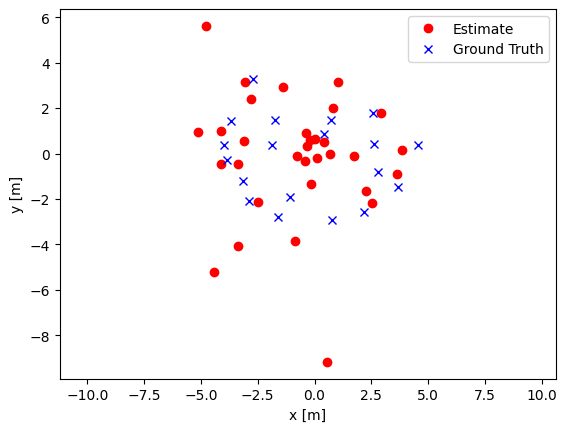

In [23]:
# load the data
rosbag_name = "/home/jtorde/data/boeing_demo/objects_2024-04-20-20-02-16.bag"
topic_list = [f"/OBJ0{i}/world" if i < 10 else f"/OBJ{i}/world" for i in range(1, 21)]
obj_gt = {topic: [] for topic in topic_list}
for topic, msg, t in  rosbag.Bag(rosbag_name).read_messages():
    if topic in topic_list:
        obj_gt[topic].append([msg.pose.position.x, msg.pose.position.y])

# only use the first one for each object
for topic in obj_gt:
    if len(obj_gt[topic]) > 1:
        obj_gt[topic] = obj_gt[topic][0]

# plot the results
plt.figure()
plt.plot(map_results[:, 0], map_results[:, 1], 'ro', label="Estimate")
for topic in obj_gt:
    if obj_gt[topic]:
        plt.plot(obj_gt[topic][0], obj_gt[topic][1], 'bx', label="Ground Truth" if topic == topic_list[0] else None)
# axis equal
plt.axis('equal')
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.legend()
plt.show()